# Galaxy Morphology Classification — Real Data (Galaxy10 DECaLS)

This notebook takes the existing CNN architecture from `mqurban/galaxy-classification` (trained originally on **synthetic** Elliptical vs. Spiral images) and re-trains/validates it on **real observational data**: the [Galaxy10 DECaLS](https://github.com/henrysky/Galaxy10) dataset.

**Galaxy10 DECaLS**: 17,736 real galaxy images (256x256, RGB) from the DESI Legacy Imaging Surveys, labeled into 10 morphology classes by Galaxy Zoo volunteers.

**Strategy:** the model architecture expects binary Elliptical vs. Spiral (64x64 grayscale), so we won't touch `model.py`. Instead we:
1. Download the real Galaxy10 DECaLS `.h5` file
2. Map its 10 classes down to 2 clean, unambiguous classes:
   - **Elliptical** = Round Smooth (2), In-between Round Smooth (3), Cigar-shaped Smooth (4)
   - **Spiral** = Barred Spiral (5), Unbarred Tight Spiral (6), Unbarred Loose Spiral (7)
   - We **drop** Disturbed (0), Merging (1), and both Edge-on classes (8, 9) — these don't map cleanly to either bucket and would just inject label noise
3. Resize to 64x64 grayscale to match the existing model's expected input
4. Reuse `GalaxyCNN` unchanged, train, and compare against the synthetic-data results

## 1. Clone the repo and install dependencies

In [2]:
!git clone https://github.com/mqurban/galaxy-classification.git
%cd galaxy-classification
!pip install -q h5py scikit-image

Cloning into 'galaxy-classification'...
remote: Enumerating objects: 42, done.
remote: Counting objects: 100% (42/42), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 42 (delta 8), reused 40 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (42/42), 4.07 MiB | 9.70 MiB/s, done.
Resolving deltas: 100% (8/8), done.
/content/galaxy-classification


## 2. Download the real Galaxy10 DECaLS dataset (~2.5 GB, from Zenodo)

In [3]:
!wget -q --show-progress -O Galaxy10_DECals.h5 https://zenodo.org/records/10845026/files/Galaxy10_DECals.h5
print("Download complete.")

Galaxy10_DECals.h5  100%[===================>]   2.55G  3.05MB/s    in 15m 15s 
Download complete.


## 3. Load, filter to binary classes, and preprocess to 64x64 grayscale

In [4]:
import h5py
import numpy as np
from skimage.transform import resize
from skimage.color import rgb2gray

IMG_SIZE = 64

# Galaxy10 DECaLS original class indices -> our binary scheme
ELLIPTICAL_CLASSES = {2, 3, 4}   # Round Smooth, In-between Round Smooth, Cigar-shaped Smooth
SPIRAL_CLASSES = {5, 6, 7}       # Barred Spiral, Unbarred Tight Spiral, Unbarred Loose Spiral
# Dropped: 0 (Disturbed), 1 (Merging), 8 (Edge-on w/o bulge), 9 (Edge-on w/ bulge)

print("Loading Galaxy10_DECals.h5 ...")
with h5py.File("Galaxy10_DECals.h5", "r") as F:
    raw_images = np.array(F["images"])   # (17736, 256, 256, 3)
    raw_labels = np.array(F["ans"])      # (17736,)

print(f"Raw dataset: {raw_images.shape[0]} images, classes present: {sorted(set(raw_labels))}")

# Keep only the classes we want, map to binary: 0 = Elliptical, 1 = Spiral
keep_mask = np.isin(raw_labels, list(ELLIPTICAL_CLASSES | SPIRAL_CLASSES))
images_filtered = raw_images[keep_mask]
labels_raw_filtered = raw_labels[keep_mask]
binary_labels = np.array([0 if lbl in ELLIPTICAL_CLASSES else 1 for lbl in labels_raw_filtered])

print(f"After filtering to clean Elliptical/Spiral classes: {images_filtered.shape[0]} images")
print(f"  Elliptical: {(binary_labels == 0).sum()}")
print(f"  Spiral:     {(binary_labels == 1).sum()}")

Loading Galaxy10_DECals.h5 ...
Raw dataset: 17736 images, classes present: [np.uint8(0), np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(9)]
After filtering to clean Elliptical/Spiral classes: 11506 images
  Elliptical: 5006
  Spiral:     6500


In [5]:
# Resize to 64x64 and convert to grayscale to match the existing GalaxyCNN input shape
def preprocess(images):
    processed = np.zeros((len(images), IMG_SIZE, IMG_SIZE), dtype=np.float32)
    for i, img in enumerate(images):
        gray = rgb2gray(img)  # (256, 256), values in [0, 1]
        resized = resize(gray, (IMG_SIZE, IMG_SIZE), anti_aliasing=True)
        processed[i] = resized
    return processed

print("Preprocessing images (resize + grayscale)... this takes a minute.")
X = preprocess(images_filtered)
y = binary_labels

X = X.reshape(-1, IMG_SIZE, IMG_SIZE, 1)  # add channel dim, matches data_generator.py's output shape
print(f"Final X shape: {X.shape}, y shape: {y.shape}")

Preprocessing images (resize + grayscale)... this takes a minute.
Final X shape: (11506, 64, 64, 1), y shape: (11506,)


## 4. Shuffle, split, and preview a few real samples

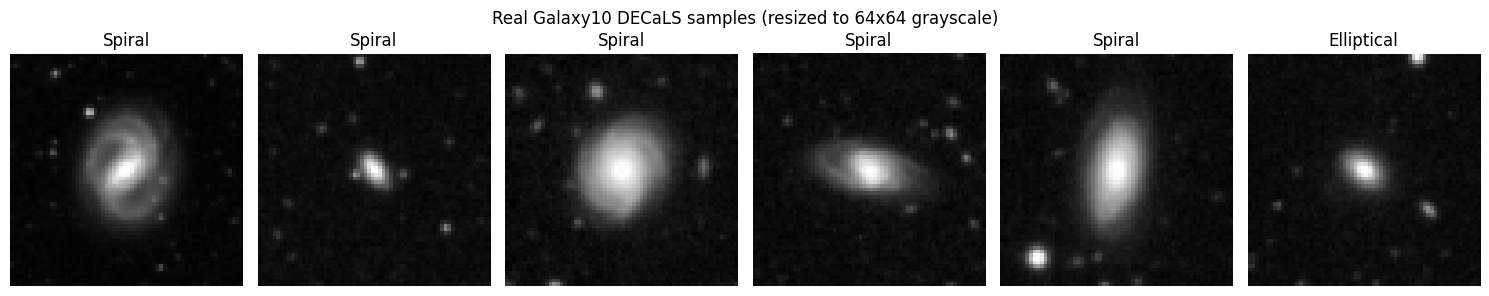

In [6]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
shuffle_idx = rng.permutation(len(X))
X, y = X[shuffle_idx], y[shuffle_idx]

label_map = {0: "Elliptical", 1: "Spiral"}
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for i, ax in enumerate(axes):
    ax.imshow(X[i].squeeze(), cmap="gray")
    ax.set_title(label_map[y[i]])
    ax.axis("off")
plt.suptitle("Real Galaxy10 DECaLS samples (resized to 64x64 grayscale)")
plt.tight_layout()
plt.savefig("real_data_samples.png")
plt.show()

## 5. Train the existing GalaxyCNN on real data (architecture unchanged)

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import sys, os
sys.path.append(os.getcwd())

from src.model import GalaxyCNN  # unchanged from the repo

BATCH_SIZE = 32
EPOCHS = 20
MODEL_SAVE_PATH = "models/galaxy_classifier_real.pth"

X_tensor = torch.tensor(X, dtype=torch.float32).permute(0, 3, 1, 2)  # (N, 1, 64, 64)
y_tensor = torch.tensor(y, dtype=torch.long)

import torchvision.transforms.v2.functional as TF
import random

class AugmentedGalaxyDataset(torch.utils.data.Dataset):
    def __init__(self, images, labels, augment=False):
        self.images = images
        self.labels = labels
        self.augment = augment

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = self.labels[idx]

        if self.augment:
            if random.random() > 0.5:
                img = TF.hflip(img)
            if random.random() > 0.5:
                img = TF.vflip(img)
            angle = random.uniform(0, 360)
            img = TF.rotate(img, angle)

        return img, label

split_idx = int(len(X) * 0.8)
train_dataset = AugmentedGalaxyDataset(X_tensor[:split_idx], y_tensor[:split_idx], augment=True)
val_dataset = AugmentedGalaxyDataset(X_tensor[split_idx:], y_tensor[split_idx:], augment=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = GalaxyCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

os.makedirs("models", exist_ok=True)

train_losses, val_losses, train_accs, val_accs = [], [], [], []

for epoch in range(EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = val_correct / val_total
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {train_loss:.4f}, Acc: {train_acc:.4f} - "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

torch.save(model.state_dict(), MODEL_SAVE_PATH)
print(f"\nModel saved to {MODEL_SAVE_PATH}")

Training samples: 9204
Validation samples: 2302
Using device: cuda
Epoch 1/20 - Loss: 0.5160, Acc: 0.7528 - Val Loss: 0.4146, Val Acc: 0.8232
Epoch 2/20 - Loss: 0.4206, Acc: 0.8161 - Val Loss: 0.3646, Val Acc: 0.8436
Epoch 3/20 - Loss: 0.3739, Acc: 0.8432 - Val Loss: 0.3406, Val Acc: 0.8579
Epoch 4/20 - Loss: 0.3476, Acc: 0.8526 - Val Loss: 0.3217, Val Acc: 0.8679
Epoch 5/20 - Loss: 0.3297, Acc: 0.8615 - Val Loss: 0.3039, Val Acc: 0.8779
Epoch 6/20 - Loss: 0.3039, Acc: 0.8729 - Val Loss: 0.3061, Val Acc: 0.8775
Epoch 7/20 - Loss: 0.2912, Acc: 0.8782 - Val Loss: 0.3764, Val Acc: 0.8406
Epoch 8/20 - Loss: 0.2779, Acc: 0.8866 - Val Loss: 0.2962, Val Acc: 0.8840
Epoch 9/20 - Loss: 0.2658, Acc: 0.8890 - Val Loss: 0.2580, Val Acc: 0.9031
Epoch 10/20 - Loss: 0.2534, Acc: 0.8963 - Val Loss: 0.2412, Val Acc: 0.9101
Epoch 11/20 - Loss: 0.2445, Acc: 0.8970 - Val Loss: 0.2397, Val Acc: 0.8983
Epoch 12/20 - Loss: 0.2365, Acc: 0.9046 - Val Loss: 0.2363, Val Acc: 0.9066
Epoch 13/20 - Loss: 0.2280, Ac

## 6. Plot training curves and prediction samples (real data)

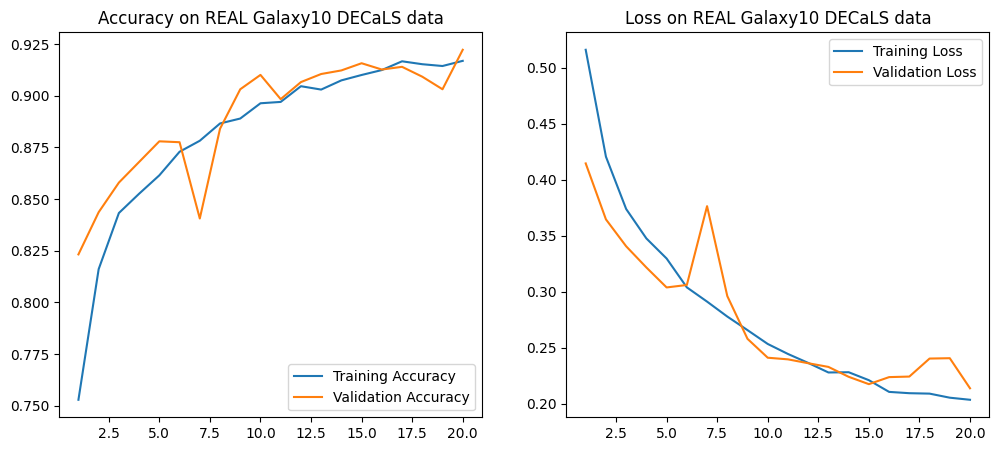

Saved to training_results_real.png


In [8]:
epochs_range = range(1, len(train_losses) + 1)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accs, label="Training Accuracy")
plt.plot(epochs_range, val_accs, label="Validation Accuracy")
plt.legend(loc="lower right")
plt.title("Accuracy on REAL Galaxy10 DECaLS data")

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_losses, label="Training Loss")
plt.plot(epochs_range, val_losses, label="Validation Loss")
plt.legend(loc="upper right")
plt.title("Loss on REAL Galaxy10 DECaLS data")

plt.savefig("training_results_real.png")
plt.show()
print("Saved to training_results_real.png")

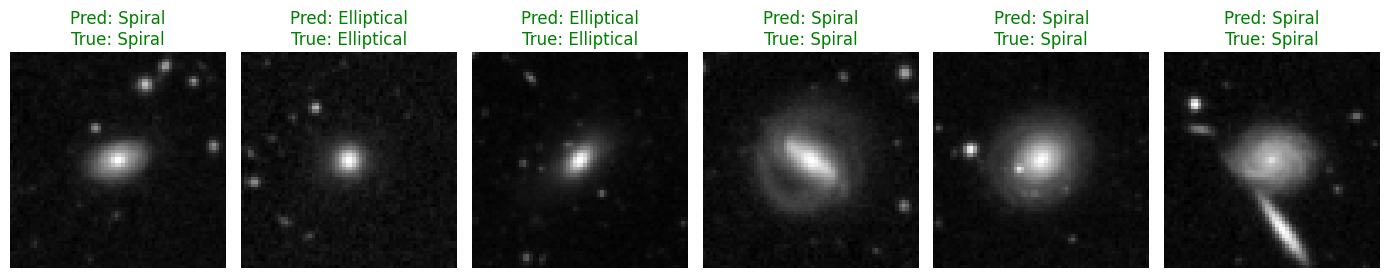

Saved to prediction_samples_real.png


In [9]:
model.eval()
data_iter = iter(val_loader)
images_batch, labels_batch = next(data_iter)

num_samples = 6
images_batch = images_batch[:num_samples].to(device)
labels_batch = labels_batch[:num_samples].to(device)

outputs = model(images_batch)
_, predictions = torch.max(outputs, 1)

plt.figure(figsize=(14, 3))
for i in range(num_samples):
    plt.subplot(1, num_samples, i + 1)
    img_np = images_batch[i].cpu().squeeze().numpy()
    plt.imshow(img_np, cmap="gray")
    predicted_label = predictions[i].item()
    true_label = labels_batch[i].item()
    color = "green" if predicted_label == true_label else "red"
    plt.title(f"Pred: {label_map[predicted_label]}\nTrue: {label_map[true_label]}", color=color)
    plt.axis("off")

plt.tight_layout()
plt.savefig("prediction_samples_real.png")
plt.show()
print("Saved to prediction_samples_real.png")

## Notes / talking points

- **Expect accuracy to drop noticeably vs. the synthetic run** (which was near-perfect). Real galaxies have variable brightness, orientation, background contamination, and genuinely ambiguous morphology near the smooth/spiral boundary — that's the whole point of this exercise. A large synthetic-to-real accuracy gap is itself a meaningful, honest result to bring up.
- If accuracy is still weak after this pass, the next real step (not needed for the call, but worth naming if asked) would be data augmentation (rotations/flips — physically justified since galaxy orientation is arbitrary) and possibly moving beyond the 3-conv-layer architecture.
- This mirrors the same **simulate-then-validate-on-real-data** workflow already described in the repo's README, which is the direct bridge to this approach of validating on synthetic data (Lyman-alpha, weak lensing) before applying methods to real survey data.